<a href="https://colab.research.google.com/github/RoqaiaWagih/ATmega_Drivers/blob/main/notebook/AI_Compression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import numpy as np

print("Python:", sys.version)
print("NumPy:", np.__version__)

Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
NumPy: 2.0.2


In [1]:

%pip install --no-cache-dir "compressai==1.2.8"


In [2]:

import torch
import numpy
import compressai

print("PyTorch:", torch.__version__)
print("NumPy:", numpy.__version__)
print("CompressAI:", compressai.__version__)

from compressai.zoo import bmshj2018_factorized

model = bmshj2018_factorized(
    quality=3,
    pretrained=True
)

model.eval()
model.update(force=True)

print("SUCCESS: AI compression model loaded!")


PyTorch: 2.11.0+cpu
NumPy: 1.26.4
CompressAI: 1.2.8
Downloading: "https://compressai.s3.amazonaws.com/models/v1/bmshj2018-factorized-prior-3-5c6f152b.pth.tar" to /root/.cache/torch/hub/checkpoints/bmshj2018-factorized-prior-3-5c6f152b.pth.tar


100%|██████████| 11.6M/11.6M [00:00<00:00, 18.1MB/s]


SUCCESS: AI compression model loaded!


In [3]:

import torch
from compressai.zoo import bmshj2018_factorized

device = torch.device("cpu")

model = bmshj2018_factorized(
    quality=3,
    pretrained=True
).to(device)

model.eval()

# Prepare entropy tables for real bitstream coding
model.update(force=True)

print("AI model loaded successfully!")
print("Model: bmshj2018_factorized")
print("Quality level: 3")


AI model loaded successfully!
Model: bmshj2018_factorized
Quality level: 3


Original dimensions: (768, 512)
Color mode: RGB


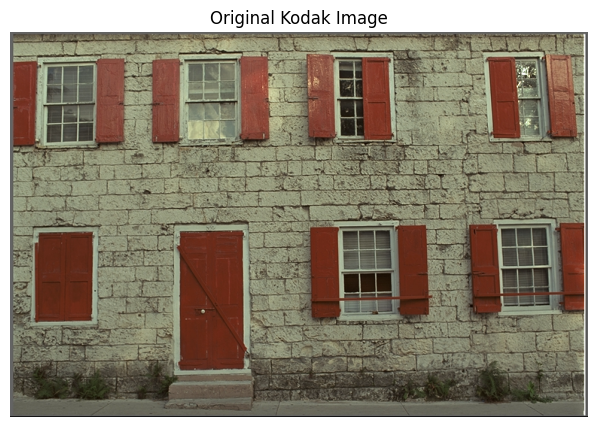

In [4]:

from pathlib import Path
import requests
from PIL import Image
import matplotlib.pyplot as plt

folder = Path("/content/DIP_Project/datasets/kodak")
folder.mkdir(parents=True, exist_ok=True)

image_path = folder / "kodim01.png"

if not image_path.exists():
    url = (
        "https://r0k.us/graphics/kodak/"
        "kodak/kodim01.png"
    )
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    image_path.write_bytes(response.content)

with Image.open(image_path) as img:
    original = img.convert("RGB")

print("Original dimensions:", original.size)
print("Color mode:", original.mode)

plt.figure(figsize=(8, 5))
plt.imshow(original)
plt.title("Original Kodak Image")
plt.axis("off")
plt.show()


**Convert the image into a tensor**

In [5]:

import torch
import torch.nn.functional as F
from torchvision.transforms.functional import to_tensor

# Convert to tensor: [1, 3, H, W]
x = to_tensor(original).unsqueeze(0).to(device)

_, channels, height, width = x.shape

# Pad to multiples of 64 for safe model operation
padding_h = (64 - height % 64) % 64
padding_w = (64 - width % 64) % 64

x_padded = F.pad(
    x,
    (0, padding_w, 0, padding_h),
    mode="constant",
    value=0
)

print("Original tensor:", x.shape)
print("Padded tensor:", x_padded.shape)


Original tensor: torch.Size([1, 3, 512, 768])
Padded tensor: torch.Size([1, 3, 512, 768])


**Compress the image using AI**


In [6]:

import time

with torch.no_grad():
    start = time.perf_counter()

    compressed = model.compress(x_padded)

    encoding_time = time.perf_counter() - start

print("Compression successful!")
print("Encoding time:", round(encoding_time, 3), "seconds")
print("Compressed tensor shape:", compressed["shape"])


Compression successful!
Encoding time: 1.384 seconds
Compressed tensor shape: torch.Size([32, 48])


**Decompress and reconstruct the image**

In [7]:

with torch.no_grad():
    start = time.perf_counter()

    decoded = model.decompress(
        compressed["strings"],
        compressed["shape"]
    )

    decoding_time = time.perf_counter() - start

x_hat = decoded["x_hat"]

# Remove padding
x_hat = x_hat[:, :, :height, :width]

# Keep values within the valid image range
x_hat = x_hat.clamp(0, 1)

print("Decompression successful!")
print("Decoded tensor:", x_hat.shape)
print("Decoding time:", round(decoding_time, 3), "seconds")


Decompression successful!
Decoded tensor: torch.Size([1, 3, 512, 768])
Decoding time: 1.876 seconds


**Display the original and reconstructed images**


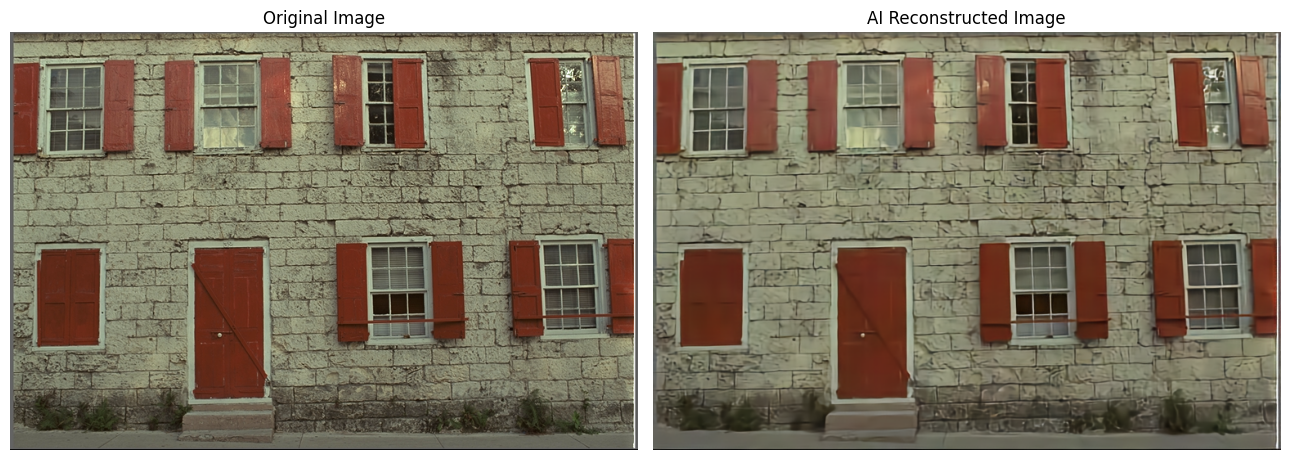

In [8]:

from torchvision.transforms.functional import to_pil_image

reconstructed = to_pil_image(x_hat.squeeze(0).cpu())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(original)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(reconstructed)
axes[1].set_title("AI Reconstructed Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [9]:

results_folder = Path("/content/DIP_Project/results")
results_folder.mkdir(parents=True, exist_ok=True)

reconstructed.save(
    results_folder / "kodim01_AI_reconstructed.png"
)

print("Reconstructed image saved!")


Reconstructed image saved!


**Measure AI compression performance**

In [10]:

import numpy as np
from skimage.metrics import peak_signal_noise_ratio

# Sum the bytes in the compressed payload
compressed_bytes = sum(
    len(stream)
    for group in compressed["strings"]
    for stream in group
)

# Preliminary payload-only bpp
bpp = 8 * compressed_bytes / (width * height)

original_array = np.array(original)
reconstructed_array = np.array(reconstructed)

psnr = peak_signal_noise_ratio(
    original_array,
    reconstructed_array,
    data_range=255
)

print("Model: Factorized Prior")
print("Compressed payload:", compressed_bytes, "bytes")
print("Payload bpp:", round(bpp, 4))
print("PSNR:", round(psnr, 2), "dB")
print("Encoding time:", round(encoding_time, 3), "s")
print("Decoding time:", round(decoding_time, 3), "s")


Model: Factorized Prior
Compressed payload: 19608 bytes
Payload bpp: 0.3989
PSNR: 27.02 dB
Encoding time: 1.384 s
Decoding time: 1.876 s


In [11]:

from compressai.zoo import (
    bmshj2018_hyperprior,
    cheng2020_anchor
)

model2 = bmshj2018_hyperprior(
    quality=3,
    pretrained=True
).to(device).eval()

model2.update(force=True)
print("Hyperprior loaded!")

model3 = cheng2020_anchor(
    quality=3,
    pretrained=True
).to(device).eval()

model3.update(force=True)
print("Cheng2020 Anchor loaded!")


Downloading: "https://compressai.s3.amazonaws.com/models/v1/bmshj2018-hyperprior-3-6d87be32.pth.tar" to /root/.cache/torch/hub/checkpoints/bmshj2018-hyperprior-3-6d87be32.pth.tar


100%|██████████| 20.2M/20.2M [00:01<00:00, 15.8MB/s]


Hyperprior loaded!
Downloading: "https://compressai.s3.amazonaws.com/models/v1/cheng2020-anchor-3-e49be189.pth.tar" to /root/.cache/torch/hub/checkpoints/cheng2020-anchor-3-e49be189.pth.tar


100%|██████████| 49.1M/49.1M [00:02<00:00, 20.3MB/s]


Cheng2020 Anchor loaded!


In [12]:

from pathlib import Path
from PIL import Image
from torchvision.transforms.functional import to_tensor
import torch.nn.functional as F

image_path = Path(
    "/content/DIP_Project/datasets/kodak/kodim01.png"
)

original = Image.open(image_path).convert("RGB")

width, height = original.size

x = to_tensor(original).unsqueeze(0).to(device)

pad_h = (64 - height % 64) % 64
pad_w = (64 - width % 64) % 64

x_padded = F.pad(
    x,
    (0, pad_w, 0, pad_h),
    mode="constant",
    value=0
)

print("Image prepared successfully!")
print("Image dimensions:", width, "x", height)


Image prepared successfully!
Image dimensions: 768 x 512


In [13]:

import time
import numpy as np
import pandas as pd

from skimage.metrics import peak_signal_noise_ratio
from torchvision.transforms.functional import to_pil_image

models = {
    "Scale Hyperprior": model2,
    "Cheng2020 Anchor": model3
}

results = []
reconstructed_images = {}

for name, current_model in models.items():

    print(f"\nTesting: {name}")

    with torch.no_grad():

        # Compress
        start = time.perf_counter()
        compressed_data = current_model.compress(x_padded)
        encoding_time = time.perf_counter() - start

        # Decompress
        start = time.perf_counter()
        decoded_data = current_model.decompress(
            compressed_data["strings"],
            compressed_data["shape"]
        )
        decoding_time = time.perf_counter() - start

    # Crop padding and clamp pixels
    x_hat = decoded_data["x_hat"]
    x_hat = x_hat[:, :, :height, :width].clamp(0, 1)

    reconstructed = to_pil_image(x_hat.squeeze(0).cpu())
    reconstructed_images[name] = reconstructed

    # Actual compressed payload size
    compressed_bytes = sum(
        len(stream)
        for group in compressed_data["strings"]
        for stream in group
    )

    bpp = 8 * compressed_bytes / (width * height)

    psnr = peak_signal_noise_ratio(
        np.array(original),
        np.array(reconstructed),
        data_range=255
    )

    results.append({
        "Model": name,
        "Quality": 3,
        "Payload Bytes": compressed_bytes,
        "Payload bpp": round(bpp, 4),
        "PSNR (dB)": round(psnr, 2),
        "Encoding Time (s)": round(encoding_time, 3),
        "Decoding Time (s)": round(decoding_time, 3)
    })

    print("Compression successful!")
    print("Payload bpp:", round(bpp, 4))
    print("PSNR:", round(psnr, 2), "dB")

df_models = pd.DataFrame(results)
display(df_models)



Testing: Scale Hyperprior
Compression successful!
Payload bpp: 0.5278
PSNR: 28.68 dB

Testing: Cheng2020 Anchor
Compression successful!
Payload bpp: 0.4657
PSNR: 28.86 dB


,Model,Quality,Payload Bytes,Payload bpp,PSNR (dB),Encoding Time (s),Decoding Time (s)
0,Scale Hyperprior,3,25940,0.5278,28.68,2.392,1.404
1,Cheng2020 Anchor,3,22888,0.4657,28.86,7.247,19.180


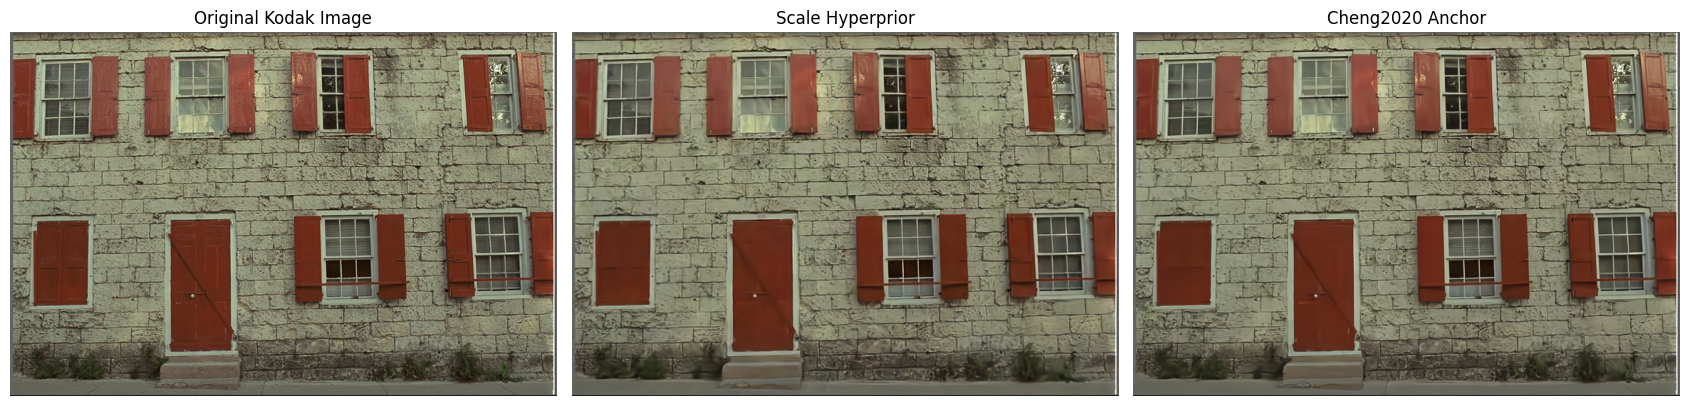

In [14]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].imshow(original)
axes[0].set_title("Original Kodak Image")

axes[1].imshow(reconstructed_images["Scale Hyperprior"])
axes[1].set_title("Scale Hyperprior")

axes[2].imshow(reconstructed_images["Cheng2020 Anchor"])
axes[2].set_title("Cheng2020 Anchor")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [16]:

from pathlib import Path

output_folder = Path("/content/DIP_Project/results")
output_folder.mkdir(parents=True, exist_ok=True)

df_models.to_csv(
    output_folder / "models_comparison.csv",
    index=False
)

for name, image in reconstructed_images.items():
    filename = name.lower().replace(" ", "_")
    image.save(output_folder / f"{filename}.png")

print("Results saved successfully!")


Results saved successfully!
